In [12]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from preprocessing import preprocess_image, preprocess_mask
from feature_extraction import build_tensor, extract_lbp, extract_canny, extract_hsv, build_bbox_map

BASE_DIR   = "Kvasir-SEG"
IMAGE_DIR  = os.path.join(BASE_DIR, "images")
MASK_DIR   = os.path.join(BASE_DIR, "masks")
SPLIT_JSON = "split_index.json"
BBOX_JSON  = os.path.join(BASE_DIR, "kavsir_bboxes.json")

with open(SPLIT_JSON) as f:
    split = json.load(f)
with open(BBOX_JSON) as f:
    bbox_data = json.load(f)

print("Imports OK")
print(f"Train: {len(split['train'])}, Val: {len(split['val'])}, Test: {len(split['test'])}")

Imports OK
Train: 800, Val: 100, Test: 100


## **Load Sample Image**

In [13]:
img_id     = split["train"][0]
image_path = os.path.join(IMAGE_DIR, img_id + ".jpg")
mask_path  = os.path.join(MASK_DIR,  img_id + ".jpg")
bbox_entry = bbox_data[img_id]

bgr_float = preprocess_image(image_path)
mask      = preprocess_mask(mask_path)
tensor    = build_tensor(bgr_float, bbox_entry)

print(f"Image ID     : {img_id}")
print(f"Tensor shape : {tensor.shape}")
print(f"Tensor dtype : {tensor.dtype}")
print(f"Tensor range : [{tensor.min():.3f}, {tensor.max():.3f}]")
print(f"Mask unique  : {np.unique(mask)}")
print(f"Original size: {bbox_entry['width']}x{bbox_entry['height']}")

Image ID     : cju5wkonqlrl409877y8zvnub
Tensor shape : (256, 256, 9)
Tensor dtype : float32
Tensor range : [0.000, 1.000]
Mask unique  : [0. 1.]
Original size: 627x547


## **Polyp Size Distribution**

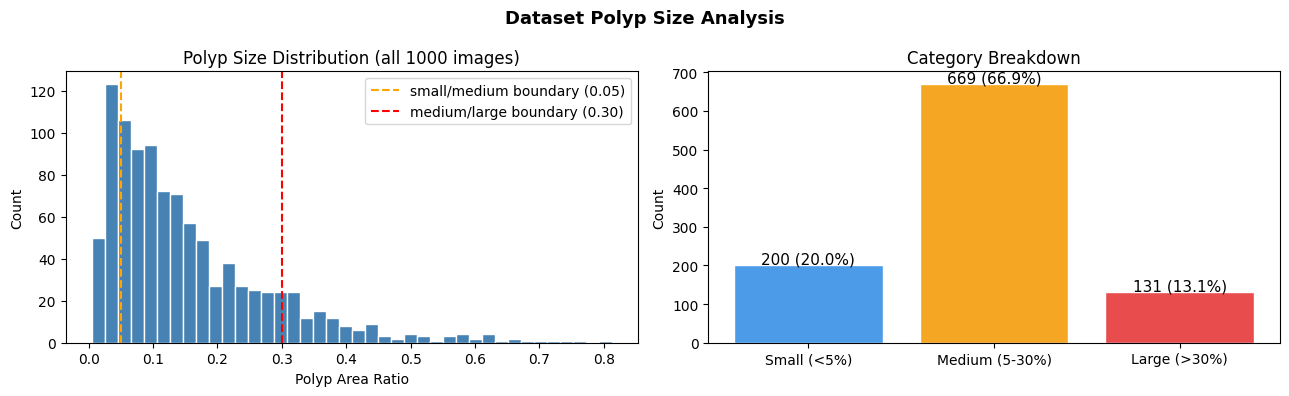

Small  :  200 (20.0%)
Medium :  669 (66.9%)
Large  :  131 (13.1%)
Mean ratio: 0.1539 | Median: 0.1140


In [14]:
from PIL import Image as PILImage

all_ids = [os.path.splitext(f)[0] for f in sorted(os.listdir(IMAGE_DIR))]
ratios  = []
for img_id in all_ids:
    mask_arr = np.array(PILImage.open(os.path.join(MASK_DIR, img_id + ".jpg")).convert("L"))
    ratios.append((mask_arr > 127).astype(np.float32).mean())
ratios = np.array(ratios)

small  = (ratios < 0.05).sum()
medium = ((ratios >= 0.05) & (ratios < 0.30)).sum()
large  = (ratios >= 0.30).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(ratios, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(0.05, color="orange", linestyle="--", label="small/medium boundary (0.05)")
axes[0].axvline(0.30, color="red",    linestyle="--", label="medium/large boundary (0.30)")
axes[0].set_xlabel("Polyp Area Ratio")
axes[0].set_ylabel("Count")
axes[0].set_title("Polyp Size Distribution (all 1000 images)")
axes[0].legend()

axes[1].bar(["Small (<5%)", "Medium (5-30%)", "Large (>30%)"],
            [small, medium, large],
            color=["#4C9BE8", "#F5A623", "#E84C4C"], edgecolor="white")
for i, v in enumerate([small, medium, large]):
    axes[1].text(i, v + 5, f"{v} ({v/10:.1f}%)", ha="center", fontsize=11)
axes[1].set_ylabel("Count")
axes[1].set_title("Category Breakdown")

plt.suptitle("Dataset Polyp Size Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Small  : {small:>4} ({small/10:.1f}%)")
print(f"Medium : {medium:>4} ({medium/10:.1f}%)")
print(f"Large  : {large:>4} ({large/10:.1f}%)")
print(f"Mean ratio: {ratios.mean():.4f} | Median: {np.median(ratios):.4f}")

## **Visualize All 9 Channels**

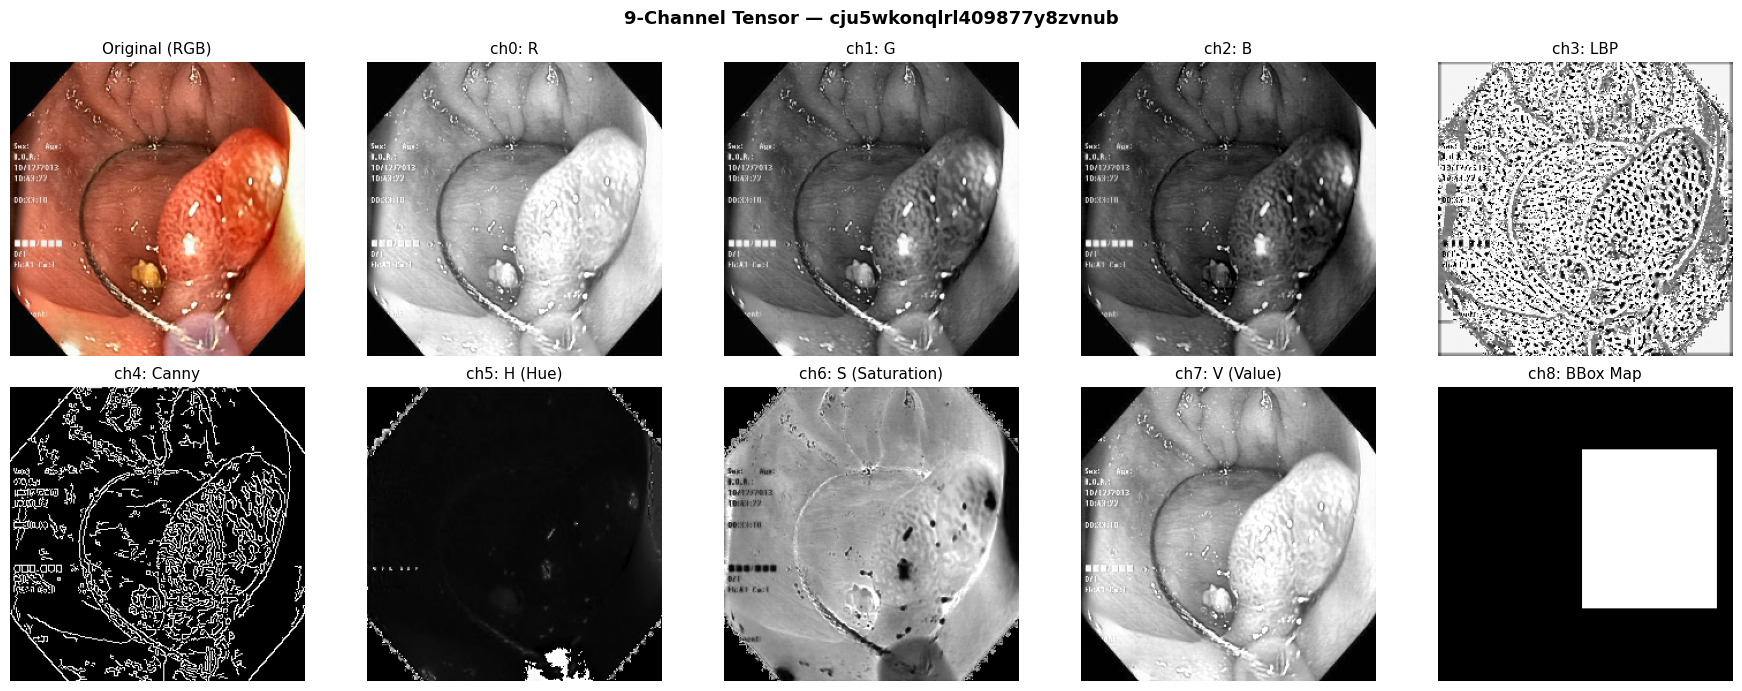

In [15]:
img_id     = split["train"][0]
bgr_float  = preprocess_image(os.path.join(IMAGE_DIR, img_id + ".jpg"))
mask       = preprocess_mask(os.path.join(MASK_DIR,  img_id + ".jpg"))
tensor     = build_tensor(bgr_float, bbox_data[img_id])

channel_names = ["R", "G", "B", "LBP", "Canny", "H (Hue)", "S (Saturation)", "V (Value)", "BBox Map"]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

axes[0].imshow(tensor[:, :, :3])
axes[0].set_title("Original (RGB)", fontsize=11)
axes[0].axis("off")

for i in range(9):
    axes[i + 1].imshow(tensor[:, :, i], cmap="gray")
    axes[i + 1].set_title(f"ch{i}: {channel_names[i]}", fontsize=11)
    axes[i + 1].axis("off")

plt.suptitle(f"9-Channel Tensor — {img_id}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Before vs After Preprocessing (CLAHE Effect)**

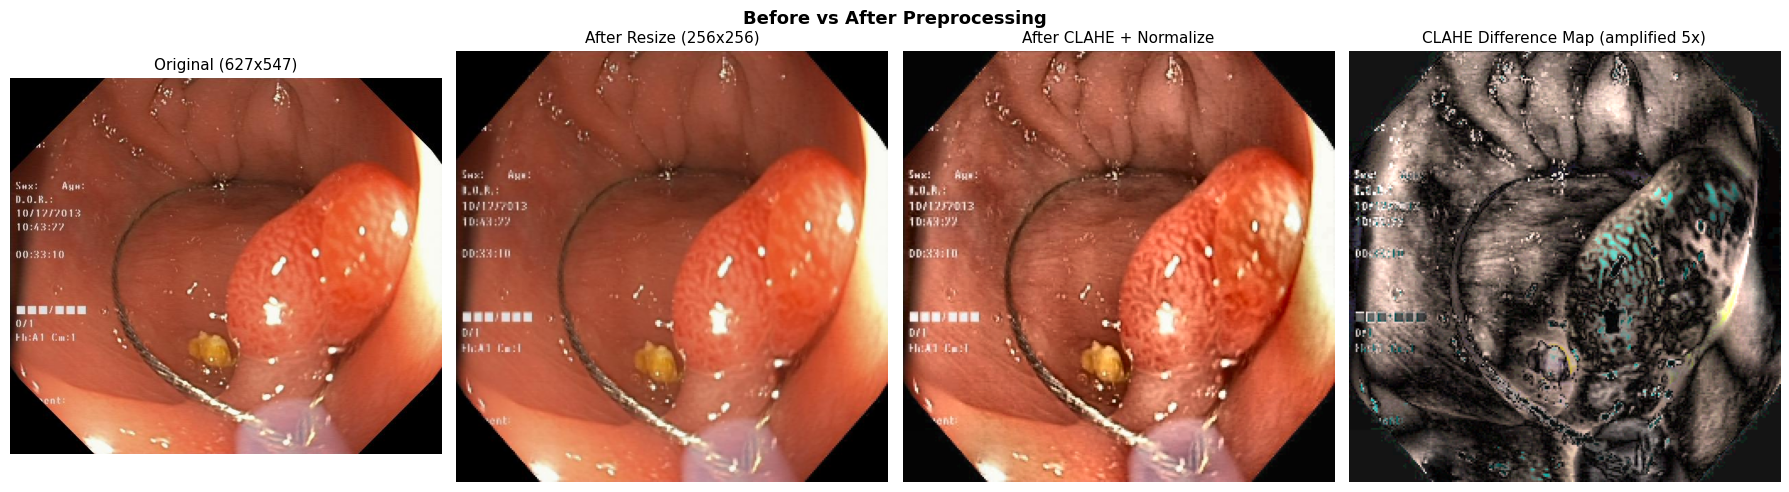

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt

raw_bgr     = cv2.imread(os.path.join(IMAGE_DIR, img_id + ".jpg"))
raw_rgb     = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

# after resize only (before CLAHE)
resized     = cv2.resize(raw_bgr, (256, 256), interpolation=cv2.INTER_LINEAR)
resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

# after CLAHE (from preprocess_image)
clahe_out   = preprocess_image(os.path.join(IMAGE_DIR, img_id + ".jpg"))
clahe_rgb   = (clahe_out[:, :, ::-1] * 255).astype(np.uint8)

# difference map: highlights what CLAHE changed (amplified for visibility)
diff          = cv2.absdiff(resized_rgb, clahe_rgb)
diff_enhanced = cv2.convertScaleAbs(diff, alpha=5)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(raw_rgb)
axes[0].set_title("Original (" + str(raw_bgr.shape[1]) + "x" + str(raw_bgr.shape[0]) + ")", fontsize=11)
axes[0].axis("off")

axes[1].imshow(resized_rgb)
axes[1].set_title("After Resize (256x256)", fontsize=11)
axes[1].axis("off")

axes[2].imshow(clahe_rgb)
axes[2].set_title("After CLAHE + Normalize", fontsize=11)
axes[2].axis("off")

axes[3].imshow(diff_enhanced)
axes[3].set_title("CLAHE Difference Map (amplified 5x)", fontsize=11)
axes[3].axis("off")

plt.suptitle("Before vs After Preprocessing", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


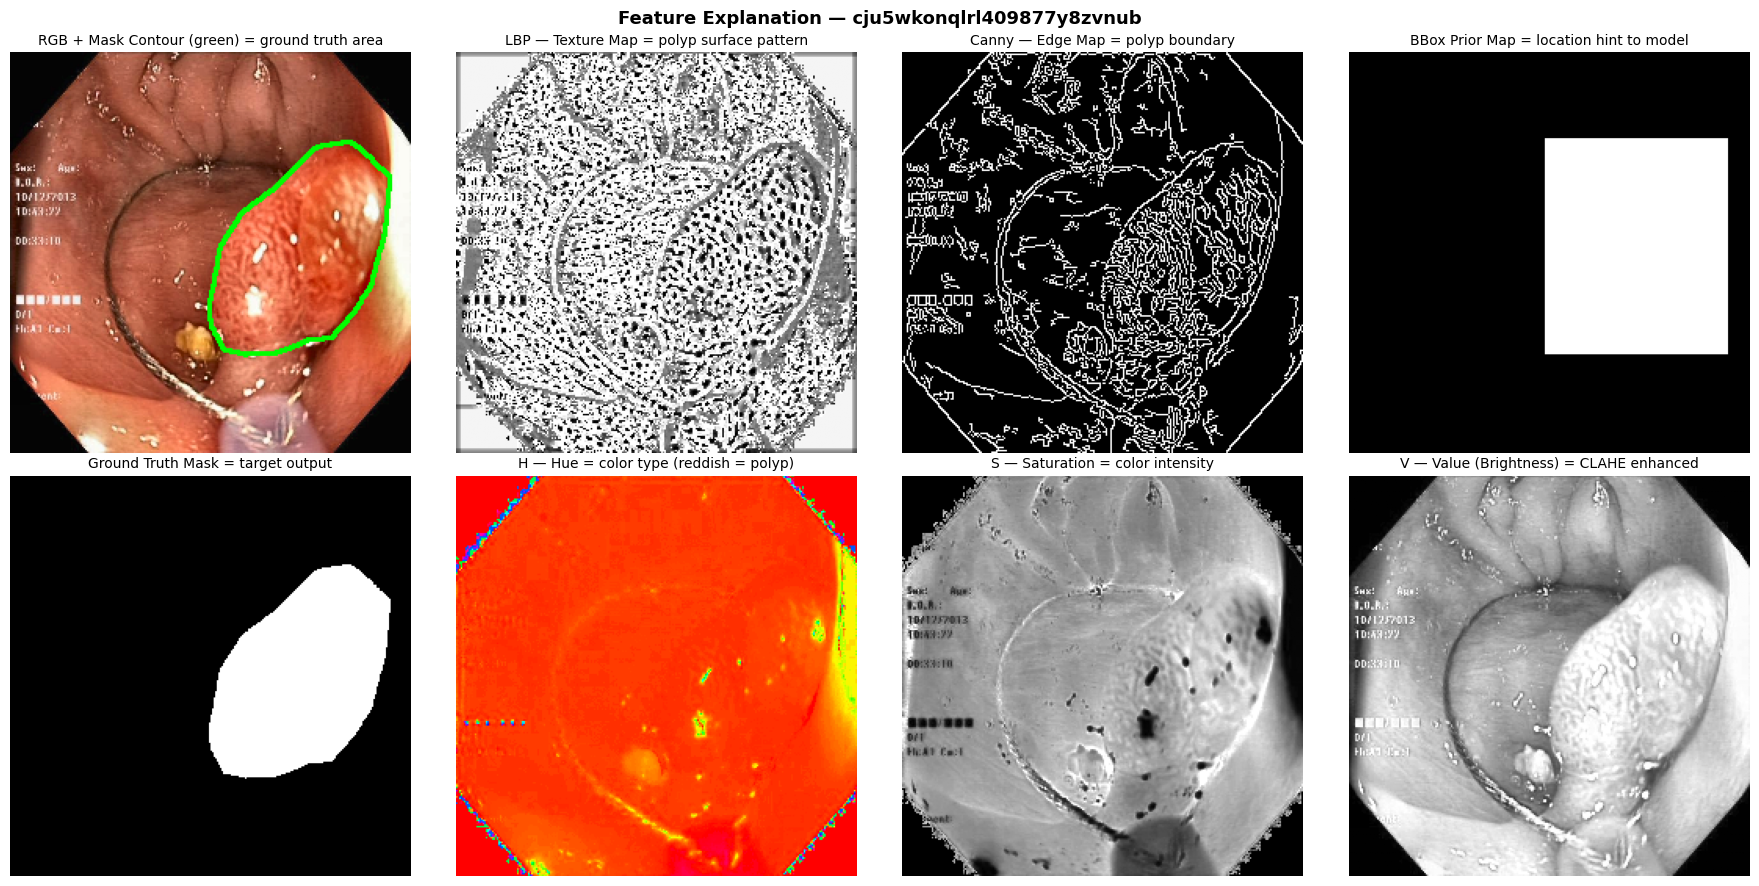

Channel summary:
  LBP   mean=0.722  -> texture richness
  Canny mean=0.157  -> edge density
  H     mean=0.058  -> dominant hue (low = reddish)
  S     mean=0.564  -> color saturation
  BBox  mean=0.246  -> fraction of image covered by bbox


In [17]:
img_path   = os.path.join(IMAGE_DIR, img_id + ".jpg")
mask_path  = os.path.join(MASK_DIR,  img_id + ".jpg")
bbox_entry = bbox_data[img_id]

bgr_float  = preprocess_image(img_path)
mask       = preprocess_mask(mask_path)
tensor     = build_tensor(bgr_float, bbox_entry)

rgb       = tensor[:, :, :3]
lbp       = tensor[:, :, 3]
canny     = tensor[:, :, 4]
h_ch      = tensor[:, :, 5]
s_ch      = tensor[:, :, 6]
v_ch      = tensor[:, :, 7]
bbox_map  = tensor[:, :, 8]

# overlay mask contour on RGB for reference
rgb_uint8    = (rgb * 255).astype(np.uint8)
mask_contour = rgb_uint8.copy()
contours, _  = cv2.findContours((mask * 255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(mask_contour, contours, -1, (0, 255, 0), 2)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(mask_contour)
axes[0, 0].set_title("RGB + Mask Contour (green) = ground truth area", fontsize=10)
axes[0, 0].axis("off")

axes[0, 1].imshow(lbp, cmap="gray")
axes[0, 1].set_title("LBP — Texture Map = polyp surface pattern", fontsize=10)
axes[0, 1].axis("off")

axes[0, 2].imshow(canny, cmap="gray")
axes[0, 2].set_title("Canny — Edge Map = polyp boundary", fontsize=10)
axes[0, 2].axis("off")

axes[0, 3].imshow(bbox_map, cmap="gray")
axes[0, 3].set_title("BBox Prior Map = location hint to model", fontsize=10)
axes[0, 3].axis("off")

axes[1, 0].imshow(mask, cmap="gray")
axes[1, 0].set_title("Ground Truth Mask = target output", fontsize=10)
axes[1, 0].axis("off")

axes[1, 1].imshow(h_ch, cmap="hsv")
axes[1, 1].set_title("H — Hue = color type (reddish = polyp)", fontsize=10)
axes[1, 1].axis("off")

axes[1, 2].imshow(s_ch, cmap="gray")
axes[1, 2].set_title("S — Saturation = color intensity", fontsize=10)
axes[1, 2].axis("off")

axes[1, 3].imshow(v_ch, cmap="gray")
axes[1, 3].set_title("V — Value (Brightness) = CLAHE enhanced", fontsize=10)
axes[1, 3].axis("off")

plt.suptitle("Feature Explanation — " + img_id, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Channel summary:")
print("  LBP   mean=" + str(round(lbp.mean(), 3)) + "  -> texture richness")
print("  Canny mean=" + str(round(canny.mean(), 3)) + "  -> edge density")
print("  H     mean=" + str(round(h_ch.mean(), 3)) + "  -> dominant hue (low = reddish)")
print("  S     mean=" + str(round(s_ch.mean(), 3)) + "  -> color saturation")
print("  BBox  mean=" + str(round(bbox_map.mean(), 3)) + "  -> fraction of image covered by bbox")


## **Image | Mask | BBox Overlay**

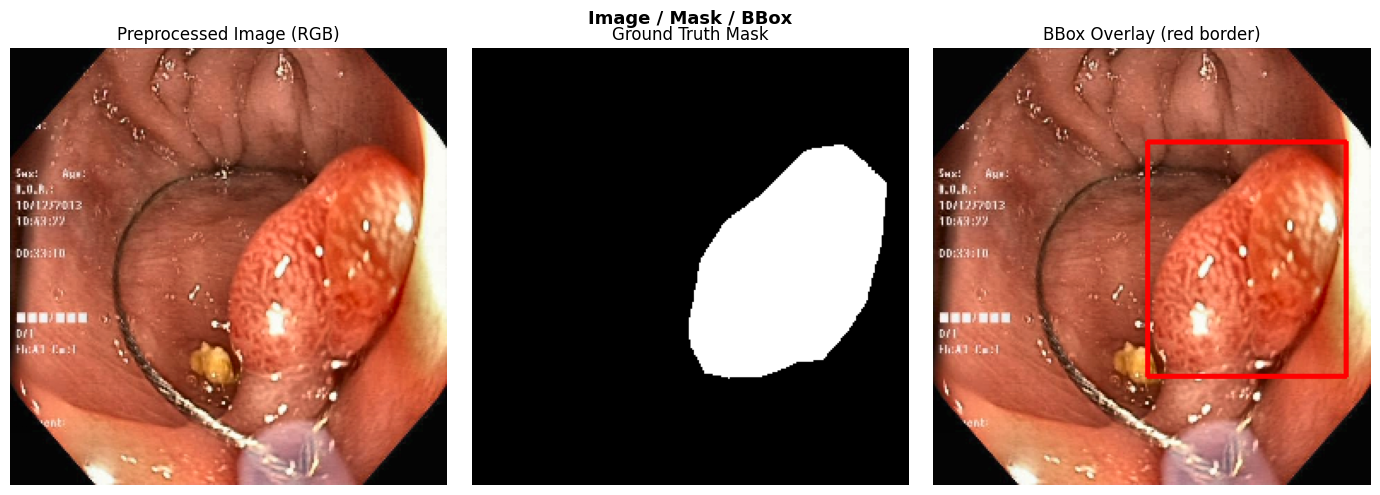

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(tensor[:, :, :3])
axes[0].set_title("Preprocessed Image (RGB)")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

bbox_ch       = tensor[:, :, 8]
overlay_uint8 = (tensor[:, :, :3] * 255).astype(np.uint8)
contours, _   = cv2.findContours(
    (bbox_ch * 255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
cv2.drawContours(overlay_uint8, contours, -1, (255, 0, 0), 2)
axes[2].imshow(overlay_uint8)
axes[2].set_title("BBox Overlay (red border)")
axes[2].axis("off")

plt.suptitle("Image / Mask / BBox", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Per-Channel Statistics**

In [19]:
channel_names = ["R", "G", "B", "LBP", "Canny", "H", "S", "V", "BBox"]

print(f"{'Ch':<4} {'Name':<8} {'Min':>6} {'Max':>6} {'Mean':>7} {'Std':>7}")
print("-" * 42)
for i, name in enumerate(channel_names):
    ch = tensor[:, :, i]
    print(f"{i:<4} {name:<8} {ch.min():>6.3f} {ch.max():>6.3f} {ch.mean():>7.3f} {ch.std():>7.3f}")

Ch   Name        Min    Max    Mean     Std
------------------------------------------
0    R         0.004  1.000   0.649   0.265
1    G         0.000  1.000   0.357   0.202
2    B         0.000  1.000   0.265   0.186
3    LBP       0.000  1.000   0.722   0.340
4    Canny     0.000  1.000   0.157   0.364
5    H         0.000  1.000   0.058   0.121
6    S         0.000  1.000   0.564   0.227
7    V         0.012  1.000   0.649   0.264
8    BBox      0.000  1.000   0.246   0.431


## **Feature Discriminability — Polyp vs Background**

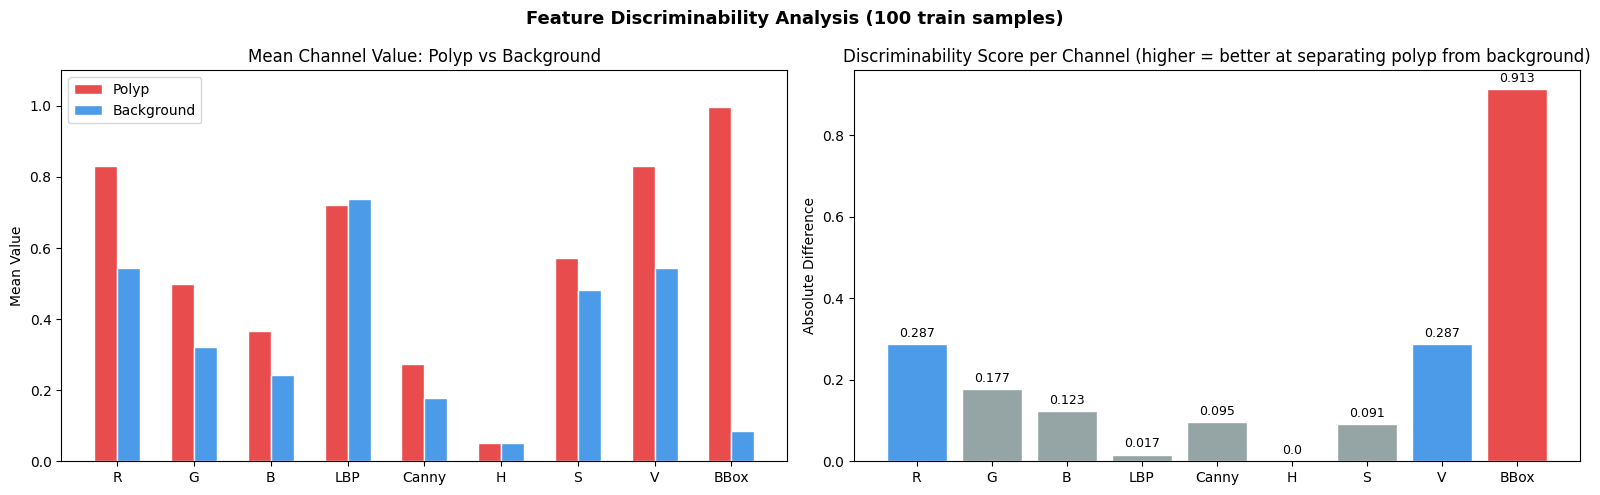

Channel Ranking (most to least discriminative):
----------------------------------------
  1. BBox   | diff=0.913 | 91%
  2. R      | diff=0.287 | 28%
  3. V      | diff=0.287 | 28%
  4. G      | diff=0.177 | 17%
  5. B      | diff=0.123 | 12%
  6. Canny  | diff=0.095 | 9%
  7. S      | diff=0.091 | 9%
  8. LBP    | diff=0.017 | 1%
  9. H      | diff=0.000 | 0%

Insight:
  BBox  has highest score — confirms bbox prior is the most discriminative feature
  R, V  high score        — polyp appears brighter/more reddish than background
  H     near zero         — hue alone is not enough to separate polyp from tissue


In [ ]:
# Compare mean channel value inside polyp vs background across 100 samples
ch_names     = ["R", "G", "B", "LBP", "Canny", "H", "S", "V", "BBox"]
polyp_means  = np.zeros(9)
bg_means     = np.zeros(9)
count        = 0

for sample_id in split["train"][:100]:
    img_path   = os.path.join(IMAGE_DIR, sample_id + ".jpg")
    mask_path  = os.path.join(MASK_DIR,  sample_id + ".jpg")
    bbox_entry = bbox_data[sample_id]

    img   = preprocess_image(img_path)
    msk   = preprocess_mask(mask_path)
    t     = build_tensor(img, bbox_entry)

    poly_px = msk == 1
    bg_px   = msk == 0

    if poly_px.sum() > 0 and bg_px.sum() > 0:
        for c in range(9):
            polyp_means[c] += t[:, :, c][poly_px].mean()
            bg_means[c]    += t[:, :, c][bg_px].mean()
        count += 1

polyp_means /= count
bg_means    /= count
diff         = np.abs(polyp_means - bg_means)

# bar chart comparison
x     = np.arange(len(ch_names))
width = 0.3

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bars1 = axes[0].bar(x - width/2, polyp_means, width, label="Polyp",     color="#E84C4C", edgecolor="white")
bars2 = axes[0].bar(x + width/2, bg_means,    width, label="Background", color="#4C9BE8", edgecolor="white")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ch_names)
axes[0].set_ylabel("Mean Value")
axes[0].set_title("Mean Channel Value: Polyp vs Background")
axes[0].legend()
axes[0].set_ylim(0, 1.1)

# difference bar (discriminability score)
colors = ["#E84C4C" if d == diff.max() else "#4C9BE8" if d >= np.percentile(diff, 66) else "#95A5A6" for d in diff]
bars   = axes[1].bar(x, diff, color=colors, edgecolor="white")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ch_names)
axes[1].set_ylabel("Absolute Difference")
axes[1].set_title("Discriminability Score per Channel (higher = better at separating polyp from background)")

# annotate values on bars
for bar, val in zip(bars, diff):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 str(round(val, 3)), ha="center", va="bottom", fontsize=9)

plt.suptitle("Feature Discriminability Analysis (100 train samples)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ranking
ranked = sorted(zip(diff, ch_names), reverse=True)
print("Channel Ranking (most to least discriminative):")
print("-" * 40)
for rank, (score, name) in enumerate(ranked, 1):
    bar = int(score * 100)
    print(f"  {rank}. {name:6s} | diff={score:.3f} | {bar}%")
print()
print("Insight:")
print("  BBox  has highest score — confirms bbox prior is the most discriminative feature")
print("  R, V  high score        — polyp appears brighter/more reddish than background")
print("  H     near zero         — hue alone is not enough to separate polyp from tissue")

## **Unit Tests: All 1000 Images**

In [21]:
all_ids = [os.path.splitext(f)[0] for f in sorted(os.listdir(IMAGE_DIR))]

passed = 0
failed = []

for img_id in all_ids:
    img_path   = os.path.join(IMAGE_DIR, img_id + ".jpg")
    mask_path  = os.path.join(MASK_DIR,  img_id + ".jpg")
    bbox_entry = bbox_data.get(img_id, {"height": None, "width": None, "bbox": []})

    try:
        img    = preprocess_image(img_path)
        mask   = preprocess_mask(mask_path)
        tensor = build_tensor(img, bbox_entry)

        assert tensor.shape == (256, 256, 9),                f"wrong shape: {tensor.shape}"
        assert tensor.dtype == np.float32,                   "wrong dtype"
        assert tensor.min() >= 0.0 and tensor.max() <= 1.0,  "range out of [0, 1]"
        assert mask.shape   == (256, 256),                   "mask shape wrong"
        assert set(np.unique(mask)).issubset({0.0, 1.0}),    "mask not binary"

        passed += 1

    except Exception as e:
        failed.append((img_id, str(e)))

print(f"Passed : {passed}/{len(all_ids)}")
print(f"Failed : {len(failed)}")
if failed:
    for fid, err in failed:
        print(f"  [{fid}] {err}")

Passed : 1000/1000
Failed : 0


## **Sample Comparison: 3 Images Side by Side**

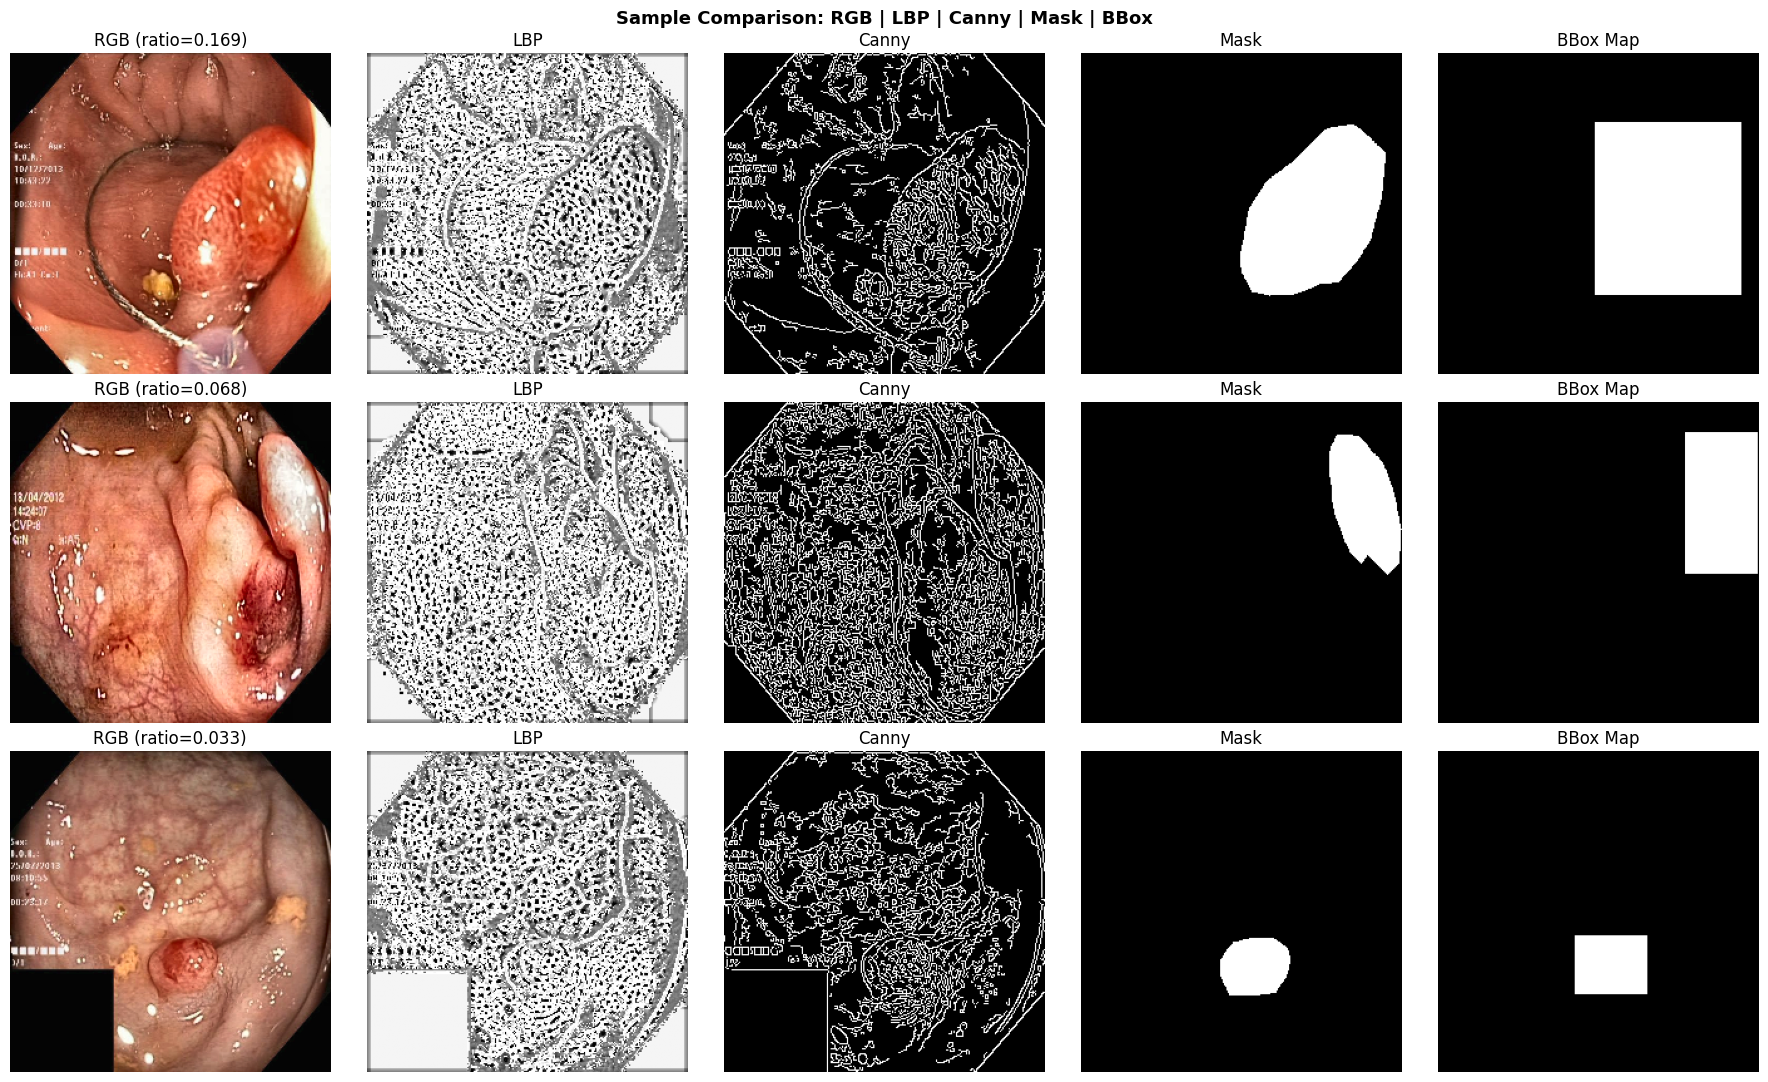

In [22]:
sample_ids = split["train"][:3]

fig, axes = plt.subplots(3, 5, figsize=(18, 11))

for row, sid in enumerate(sample_ids):
    img_path   = os.path.join(IMAGE_DIR, sid + ".jpg")
    mask_path  = os.path.join(MASK_DIR,  sid + ".jpg")
    bbox_entry = bbox_data[sid]

    img  = preprocess_image(img_path)
    mask = preprocess_mask(mask_path)
    t    = build_tensor(img, bbox_entry)

    ratio = mask.mean()

    axes[row, 0].imshow(t[:, :, :3]);             axes[row, 0].set_title(f"RGB (ratio={ratio:.3f})")
    axes[row, 1].imshow(t[:, :, 3], cmap="gray"); axes[row, 1].set_title("LBP")
    axes[row, 2].imshow(t[:, :, 4], cmap="gray"); axes[row, 2].set_title("Canny")
    axes[row, 3].imshow(mask,        cmap="gray"); axes[row, 3].set_title("Mask")
    axes[row, 4].imshow(t[:, :, 8], cmap="gray"); axes[row, 4].set_title("BBox Map")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("Sample Comparison: RGB | LBP | Canny | Mask | BBox", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()